In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit import DataStructs
from rdkit.Chem import AllChem
import seaborn as sns
import scipy.stats  # Added for statistical testing

## Data

In [11]:
## first Bayer Seed
#m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
#m1_name = "BCS-CN20332" 

## second seed
#m2 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
#m2_name = "BCS-CE65417"

# Replace with your seed SMILES
seed_smiles = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"  
input_file_1 = "../data/interim/molmim/unguided/molmmim_BCS-CN20332_LogP_sim03_100p_100m.csv"
input_file_2 = "../data/interim/molmim/guided/molmmim-Guided_BCS-CN20332_batch1_n100_Logp.csv" 

In [12]:
df1 = pd.read_csv(input_file_1, sep=";")
df2 = pd.read_csv(input_file_2, sep=";")

In [13]:
df1.head()

,smiles,score,LogP,QED
0,COC(=O)C1(CS(=O)(=O)N2C[C@@H]3[C@H](C2)[C@H]2C...,-3.624583,0.54470,0.556689
1,COC(=O)CCNC(=O)C1(C)CC(N[C@@H]2CCN(C)C2=O)C1,-2.055173,-0.34530,0.655055
2,COC(=O)CCNC(=O)C1(C)CC(N[C@@H]2CCN(C)C2=O)C1,-2.055173,-0.34530,0.655055
3,Cc1nnsc1CNC[C@@H](O)C1(Cl)CC1,-1.921801,1.06842,0.764626
4,COC(=O)CCNC(=O)C1(C)CC(N[C@@H]2CCN(C)C2)C1,-1.561663,0.12810,0.681966


In [14]:
df2.head()

,valid_smiles,LogP,QED
0,COC(=O)CCNC(=O)c1ccc(-c2cccs2)cc1,2.70800,0.861041
1,COC(=O)CCNC(=O)c1ccc(-n2ccc(C(F)(F)F)n2)cc1,2.18400,0.846314
2,COC(=O)CCNC(=O)c1ccc(NC(=O)c2cc(C)ccc2C)cc1,2.84864,0.781427
3,COC(=O)CCNC(=O)c1ccc(NC(=O)c2ccc(C)cc2)cc1,2.54022,0.791604
4,COC(=O)CCNC(=O)c1ccc(CNC(=O)Nc2cccc(N)c2)cc1,1.88340,0.437766


## Analysis

In [15]:
from molmim.by_scorer_new import MoleculeScorer

scorer = MoleculeScorer.create_scorer(
    use_qsar_hsec=True,
    use_qsar_aih=True,
    use_qed = False,
    use_similarity=False,
    similarity_weight=1.0,
    similarity_threshold=1.0,
)
#df1['AIH'] = scorer2.get_qsar_aih_predictions(df1['smiles'])
#df1['HSEC'] = scorer2.get_qsar_hsec_predictions(df1['smiles'])
#df2['AIH'] = scorer2.get_qsar_aih_predictions(df2['valid_smiles'])
#df2['HSEC'] = scorer2.get_qsar_hsec_predictions(df2['valid_smiles'])

In [17]:
results = scorer.score(df1['smiles'])
df1['AIH'] = results.norm_qsar_aih_scores
df1['HSEC'] = results.norm_qsar_hsec_scores

#~now scoring~#
Prediction failed for ID 21: 2025-03-19 15:56:28,847 ERROR Failed to standardize input structure 'COC(=O)CCNC(=O)C1(C)CC2(CC(=O)N2CC[C@H]2CO)C1'
Traceback (most recent call last):
  File "/var/task/mother/preprocessing/transformers.py", line 71, in _transform
    with m_chem.RaiseRDKitErrors():
         ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/task/mother/chem.py", line 128, in __exit__
    raise RDKitException(self.clean_error_msg(stderr))
mother.chem.RDKitException: SMILES Parse Error: unclosed ring for input: 'COC(=O)CCNC(=O)C1(C)CC2(CC(=O)N2CC[C@H]2CO)C1'
Prediction failed for ID 22: Unknown error
Prediction failed for ID 23: 2025-03-19 15:56:28,849 ERROR Failed to standardize input structure 'COC(=O)CCNC(=O)C1(C)CC2(CC(=O)N2CC[C@H](O)C2)C1'
Traceback (most recent call last):
  File "/var/task/mother/preprocessing/transformers.py", line 71, in _transform
    with m_chem.RaiseRDKitErrors():
         ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/task/mother/chem.py", line 128,

In [19]:
results2 = scorer.score(df2['valid_smiles'])
df2['AIH'] = results2.norm_qsar_aih_scores
df2['HSEC'] = results2.norm_qsar_hsec_scores

#~now scoring~#
#~Done scoring~#


In [20]:
df2.head()

,valid_smiles,LogP,QED,AIH,HSEC
0,COC(=O)CCNC(=O)c1ccc(-c2cccs2)cc1,2.70800,0.861041,0.139545,0.163400
1,COC(=O)CCNC(=O)c1ccc(-n2ccc(C(F)(F)F)n2)cc1,2.18400,0.846314,0.137800,0.208764
2,COC(=O)CCNC(=O)c1ccc(NC(=O)c2cc(C)ccc2C)cc1,2.84864,0.781427,0.142273,0.206345
3,COC(=O)CCNC(=O)c1ccc(NC(=O)c2ccc(C)cc2)cc1,2.54022,0.791604,0.106291,0.177636
4,COC(=O)CCNC(=O)c1ccc(CNC(=O)Nc2cccc(N)c2)cc1,1.88340,0.437766,0.155600,0.198109


In [21]:
df1.head()

,smiles,score,LogP,QED,AIH,HSEC
0,COC(=O)C1(CS(=O)(=O)N2C[C@@H]3[C@H](C2)[C@H]2C...,-3.624583,0.54470,0.556689,0.198964,0.260891
1,COC(=O)CCNC(=O)C1(C)CC(N[C@@H]2CCN(C)C2=O)C1,-2.055173,-0.34530,0.655055,0.161018,0.136491
2,COC(=O)CCNC(=O)C1(C)CC(N[C@@H]2CCN(C)C2=O)C1,-2.055173,-0.34530,0.655055,0.161018,0.136491
3,Cc1nnsc1CNC[C@@H](O)C1(Cl)CC1,-1.921801,1.06842,0.764626,0.099164,0.129800
4,COC(=O)CCNC(=O)C1(C)CC(N[C@@H]2CCN(C)C2)C1,-1.561663,0.12810,0.681966,0.121364,0.135145


<Figure size 1200x800 with 0 Axes>

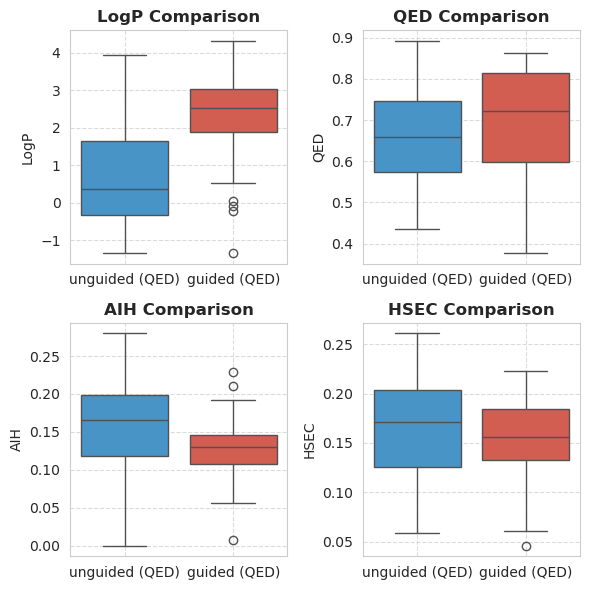

In [22]:
def create_comparison_boxplots(df1, df2, columns=['LogP', 'QED', 'AIH', 'HSEC'], name1 ='Dataset 1', name2 ='Dataset 2' ):
    # Set figure size and style
    plt.figure(figsize=(12, 8))
    sns.set_style("whitegrid")
    
    # Create subplots - one for each column
    fig, axes = plt.subplots(2, 2, figsize=(6, 6))
    axes = axes.flatten()
    
    # Define colors for each dataframe
    colors = ['#3498db', '#e74c3c']
    
    # Create boxplots for each column
    for i, column in enumerate(columns):
        # Create a temporary dataframe for plotting
        temp_df = pd.DataFrame({
            name1: df1[column],
            name2: df2[column]
        })
        
        # Melt the dataframe for seaborn
        melted_df = pd.melt(temp_df, var_name='Dataset', value_name=column)
        
        # Create boxplot
        #sns.boxplot(x='Dataset', y=column, data=melted_df, palette=colors, ax=axes[i])
        # Create boxplot (using hue instead of palette to avoid FutureWarning)
        sns.boxplot(x='Dataset', y=column, hue='Dataset', data=melted_df, palette=colors, legend=False, ax=axes[i])
        
        # Set title and style
        axes[i].set_title(f'{column} Comparison', fontweight='bold')
        axes[i].set_xlabel('')
        axes[i].grid(True, linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    plt.show()


create_comparison_boxplots(df1, df2, name1="unguided (QED)", name2="guided (QED)")
